In [201]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [202]:
df = pd.read_csv("../data/raw/obras_produtividade.csv")

In [203]:
df.head()

,id_registro,obra,cidade,data,equipe,trabalhadores,servico,condicao_climatica,horas_trabalhadas,quantidade_planejada,quantidade_executada,custo_unitario,custo_realizado,dias_atraso,horas_retrabalho,indice_qualidade,ano,mes,mes_ano
0,1,Condomínio Vila Verde,Vitória,2025-05-23,Equipe B,10,Instalações Hidráulicas,Chuva,83.5,50.7,53.8,145,8751.49,4,0.7,100.0,2025,5,2025-05
1,2,Residencial Vitória Park,Vitória,2025-01-31,Equipe D,8,Acabamento,Normal,69.4,34.8,50.5,110,5349.06,0,2.3,88.8,2025,1,2025-01
2,3,Residencial Parque Azul,Linhares,2026-03-06,Equipe A,8,Acabamento,Normal,51.9,34.2,31.1,110,3507.00,0,0.3,100.0,2026,3,2026-03
3,4,Edifício Atlântico,Serra,2025-12-15,Equipe B,11,Fundação,Normal,86.4,96.2,77.3,320,23658.73,2,0.0,100.0,2025,12,2025-12
4,5,Residencial Parque Azul,Serra,2025-04-10,Equipe A,9,Estrutura,Normal,67.8,75.8,66.4,410,31258.11,1,0.0,100.0,2025,4,2025-04


In [204]:
df.shape

(1200, 19)

In [205]:
print("Valores ausentes por coluna:")
print(df.isnull().sum())

print("\nTotal de registros duplicados:")
print(df.duplicated().sum())

Valores ausentes por coluna:
id_registro             0
obra                    0
cidade                  0
data                    0
equipe                  0
trabalhadores           0
servico                 0
condicao_climatica      0
horas_trabalhadas       0
quantidade_planejada    0
quantidade_executada    0
custo_unitario          0
custo_realizado         0
dias_atraso             0
horas_retrabalho        0
indice_qualidade        0
ano                     0
mes                     0
mes_ano                 0
dtype: int64

Total de registros duplicados:
0


In [206]:
df.columns

Index(['id_registro', 'obra', 'cidade', 'data', 'equipe', 'trabalhadores',
       'servico', 'condicao_climatica', 'horas_trabalhadas',
       'quantidade_planejada', 'quantidade_executada', 'custo_unitario',
       'custo_realizado', 'dias_atraso', 'horas_retrabalho',
       'indice_qualidade', 'ano', 'mes', 'mes_ano'],
      dtype='str')

In [207]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_registro           1200 non-null   int64  
 1   obra                  1200 non-null   str    
 2   cidade                1200 non-null   str    
 3   data                  1200 non-null   str    
 4   equipe                1200 non-null   str    
 5   trabalhadores         1200 non-null   int64  
 6   servico               1200 non-null   str    
 7   condicao_climatica    1200 non-null   str    
 8   horas_trabalhadas     1200 non-null   float64
 9   quantidade_planejada  1200 non-null   float64
 10  quantidade_executada  1200 non-null   float64
 11  custo_unitario        1200 non-null   int64  
 12  custo_realizado       1200 non-null   float64
 13  dias_atraso           1200 non-null   int64  
 14  horas_retrabalho      1200 non-null   float64
 15  indice_qualidade      1200 non-n

In [208]:
df["data"] = pd.to_datetime(df["data"])

In [209]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   id_registro           1200 non-null   int64         
 1   obra                  1200 non-null   str           
 2   cidade                1200 non-null   str           
 3   data                  1200 non-null   datetime64[us]
 4   equipe                1200 non-null   str           
 5   trabalhadores         1200 non-null   int64         
 6   servico               1200 non-null   str           
 7   condicao_climatica    1200 non-null   str           
 8   horas_trabalhadas     1200 non-null   float64       
 9   quantidade_planejada  1200 non-null   float64       
 10  quantidade_executada  1200 non-null   float64       
 11  custo_unitario        1200 non-null   int64         
 12  custo_realizado       1200 non-null   float64       
 13  dias_atraso           1200 no

In [210]:
df.describe()

,id_registro,data,trabalhadores,horas_trabalhadas,quantidade_planejada,quantidade_executada,custo_unitario,custo_realizado,dias_atraso,horas_retrabalho,indice_qualidade,ano,mes
count,1200.000000,1200,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,600.500000,2025-09-28 16:04:48,8.007500,63.98350,58.950417,60.008500,187.520833,12345.816058,2.852500,1.455917,95.025250,2025.311667,5.702500
min,1.000000,2025-01-01 00:00:00,5.000000,25.70000,19.300000,24.600000,85.000000,2135.340000,0.000000,0.000000,81.200000,2025.000000,1.000000
25%,300.750000,2025-05-19 00:00:00,7.000000,53.10000,44.900000,46.875000,120.000000,5747.595000,0.000000,0.400000,92.200000,2025.000000,3.000000
50%,600.500000,2025-10-02 12:00:00,8.000000,64.50000,55.200000,56.150000,145.000000,8390.810000,2.000000,1.400000,95.500000,2025.000000,5.000000
75%,900.250000,2026-02-06 00:00:00,9.000000,74.70000,68.900000,69.525000,210.000000,13196.640000,5.000000,2.200000,98.600000,2026.000000,8.000000
max,1200.000000,2026-06-23 00:00:00,11.000000,101.20000,135.800000,127.400000,410.000000,49126.350000,13.000000,5.700000,100.000000,2026.000000,12.000000
std,346.554469,NaN,1.604033,14.52299,20.017602,18.122415,99.221740,9879.861450,2.890393,1.134940,4.067648,0.463368,3.373447


In [211]:
df["obra"].nunique()

10

In [212]:
df["cidade"].nunique()

6

In [213]:
df["servico"].nunique()

10

In [214]:
df["equipe"].nunique()

5

In [215]:
df["servico"].unique()

<ArrowStringArray>
['Instalações Hidráulicas',              'Acabamento',
                'Fundação',               'Estrutura',
               'Cobertura',   'Instalações Elétricas',
            'Pavimentação',                 'Pintura',
            'Revestimento',               'Alvenaria']
Length: 10, dtype: str

In [216]:
df["servico"].value_counts()

servico
Pavimentação               142
Cobertura                  134
Acabamento                 129
Estrutura                  129
Pintura                    126
Fundação                   114
Alvenaria                  113
Instalações Hidráulicas    106
Revestimento               104
Instalações Elétricas      103
Name: count, dtype: int64

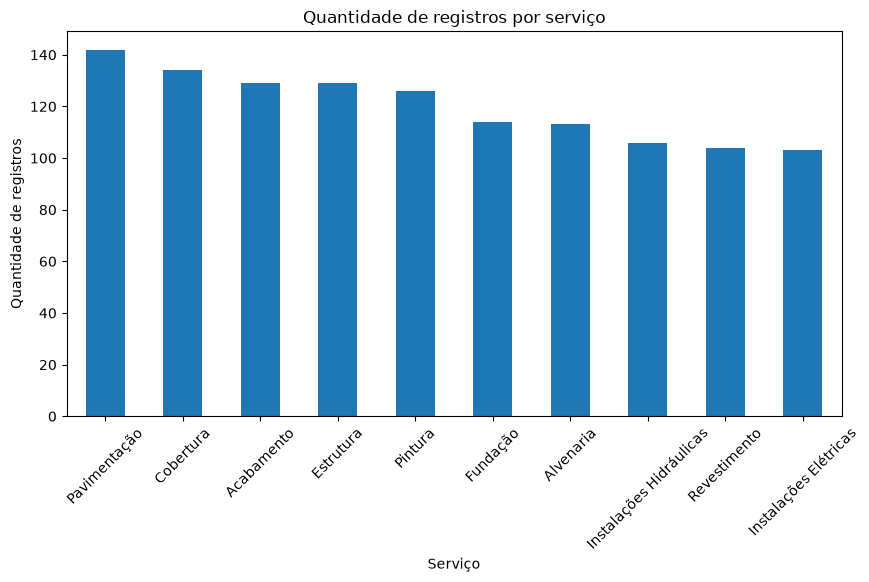

In [217]:
df["servico"].value_counts().plot(kind="bar", figsize=(10,5))

plt.title("Quantidade de registros por serviço")
plt.xlabel("Serviço")
plt.ylabel("Quantidade de registros")

plt.xticks(rotation=45)
plt.show()

In [218]:
df_tratado = df.copy()

In [219]:
df_tratado.isnull().sum()

id_registro             0
obra                    0
cidade                  0
data                    0
equipe                  0
trabalhadores           0
servico                 0
condicao_climatica      0
horas_trabalhadas       0
quantidade_planejada    0
quantidade_executada    0
custo_unitario          0
custo_realizado         0
dias_atraso             0
horas_retrabalho        0
indice_qualidade        0
ano                     0
mes                     0
mes_ano                 0
dtype: int64

In [220]:
percentual_nulos = (
    df_tratado.isnull().mean() * 100
).sort_values(ascending=False)

percentual_nulos

id_registro             0.0
obra                    0.0
cidade                  0.0
data                    0.0
equipe                  0.0
trabalhadores           0.0
servico                 0.0
condicao_climatica      0.0
horas_trabalhadas       0.0
quantidade_planejada    0.0
quantidade_executada    0.0
custo_unitario          0.0
custo_realizado         0.0
dias_atraso             0.0
horas_retrabalho        0.0
indice_qualidade        0.0
ano                     0.0
mes                     0.0
mes_ano                 0.0
dtype: float64

In [221]:
df_tratado.duplicated().sum()

np.int64(0)

In [222]:
df_tratado["id_registro"].duplicated().sum()

np.int64(0)

In [223]:
df_tratado.dtypes

id_registro                      int64
obra                               str
cidade                             str
data                    datetime64[us]
equipe                             str
trabalhadores                    int64
servico                            str
condicao_climatica                 str
horas_trabalhadas              float64
quantidade_planejada           float64
quantidade_executada           float64
custo_unitario                   int64
custo_realizado                float64
dias_atraso                      int64
horas_retrabalho               float64
indice_qualidade               float64
ano                              int64
mes                              int64
mes_ano                            str
dtype: object

In [224]:
df_tratado["indice_qualidade"].describe()

count    1200.000000
mean       95.025250
std         4.067648
min        81.200000
25%        92.200000
50%        95.500000
75%        98.600000
max       100.000000
Name: indice_qualidade, dtype: float64

In [225]:
df_tratado[
    (df_tratado["indice_qualidade"] < 0) |
    (df_tratado["indice_qualidade"] > 100)
]

,id_registro,obra,cidade,data,equipe,trabalhadores,servico,condicao_climatica,horas_trabalhadas,quantidade_planejada,quantidade_executada,custo_unitario,custo_realizado,dias_atraso,horas_retrabalho,indice_qualidade,ano,mes,mes_ano


In [226]:
df_tratado["trabalhadores"].describe()

count    1200.000000
mean        8.007500
std         1.604033
min         5.000000
25%         7.000000
50%         8.000000
75%         9.000000
max        11.000000
Name: trabalhadores, dtype: float64

In [227]:
sorted(df_tratado["servico"].unique())

['Acabamento',
 'Alvenaria',
 'Cobertura',
 'Estrutura',
 'Fundação',
 'Instalações Elétricas',
 'Instalações Hidráulicas',
 'Pavimentação',
 'Pintura',
 'Revestimento']

In [228]:
df_tratado["produtividade"] = (
    df_tratado["quantidade_executada"] /
    df_tratado["horas_trabalhadas"]
)

In [229]:
df_tratado[
    ["servico", "horas_trabalhadas",
     "quantidade_executada", "produtividade"]
].head()

,servico,horas_trabalhadas,quantidade_executada,produtividade
0,Instalações Hidráulicas,83.5,53.8,0.644311
1,Acabamento,69.4,50.5,0.727666
2,Acabamento,51.9,31.1,0.599229
3,Fundação,86.4,77.3,0.894676
4,Estrutura,67.8,66.4,0.979351


In [230]:
df_tratado["custo_por_unidade"] = (
    df_tratado["custo_realizado"] /
    df_tratado["quantidade_executada"]
)

In [231]:
df_tratado[
    ["servico", "custo_realizado",
     "quantidade_executada", "custo_por_unidade"]
].head()

,servico,custo_realizado,quantidade_executada,custo_por_unidade
0,Instalações Hidráulicas,8751.49,53.8,162.667100
1,Acabamento,5349.06,50.5,105.921980
2,Acabamento,3507.00,31.1,112.765273
3,Fundação,23658.73,77.3,306.063777
4,Estrutura,31258.11,66.4,470.754669


In [232]:
df_tratado["desvio_quantidade_pct"] = (
    (
        df_tratado["quantidade_executada"] -
        df_tratado["quantidade_planejada"]
    )
    / df_tratado["quantidade_planejada"]
) * 100

In [233]:
df_tratado[
    [
        "servico",
        "quantidade_planejada",
        "quantidade_executada",
        "desvio_quantidade_pct"
    ]
].head()

,servico,quantidade_planejada,quantidade_executada,desvio_quantidade_pct
0,Instalações Hidráulicas,50.7,53.8,6.114398
1,Acabamento,34.8,50.5,45.114943
2,Acabamento,34.2,31.1,-9.064327
3,Fundação,96.2,77.3,-19.646570
4,Estrutura,75.8,66.4,-12.401055


In [234]:
df_tratado["status_atraso"] = np.where(
    df_tratado["dias_atraso"] > 0,
    "Com atraso",
    "No prazo"
)

In [235]:
df_tratado["status_atraso"].value_counts()

status_atraso
Com atraso    822
No prazo      378
Name: count, dtype: int64

In [236]:
df_tratado["faixa_qualidade"] = pd.cut(
    df_tratado["indice_qualidade"],
    bins=[0, 80, 90, 100],
    labels=["Baixa", "Média", "Alta"],
    include_lowest=True
)

In [237]:
df_tratado["faixa_qualidade"].value_counts()

faixa_qualidade
Alta     1044
Média     156
Baixa       0
Name: count, dtype: int64

In [238]:
df_tratado.head()

,id_registro,obra,cidade,data,equipe,trabalhadores,servico,condicao_climatica,horas_trabalhadas,quantidade_planejada,...,horas_retrabalho,indice_qualidade,ano,mes,mes_ano,produtividade,custo_por_unidade,desvio_quantidade_pct,status_atraso,faixa_qualidade
0,1,Condomínio Vila Verde,Vitória,2025-05-23,Equipe B,10,Instalações Hidráulicas,Chuva,83.5,50.7,...,0.7,100.0,2025,5,2025-05,0.644311,162.667100,6.114398,Com atraso,Alta
1,2,Residencial Vitória Park,Vitória,2025-01-31,Equipe D,8,Acabamento,Normal,69.4,34.8,...,2.3,88.8,2025,1,2025-01,0.727666,105.921980,45.114943,No prazo,Média
2,3,Residencial Parque Azul,Linhares,2026-03-06,Equipe A,8,Acabamento,Normal,51.9,34.2,...,0.3,100.0,2026,3,2026-03,0.599229,112.765273,-9.064327,No prazo,Alta
3,4,Edifício Atlântico,Serra,2025-12-15,Equipe B,11,Fundação,Normal,86.4,96.2,...,0.0,100.0,2025,12,2025-12,0.894676,306.063777,-19.646570,Com atraso,Alta
4,5,Residencial Parque Azul,Serra,2025-04-10,Equipe A,9,Estrutura,Normal,67.8,75.8,...,0.0,100.0,2025,4,2025-04,0.979351,470.754669,-12.401055,Com atraso,Alta


In [239]:
df_tratado["produtividade"].describe()

count    1200.000000
mean        0.976846
std         0.339094
min         0.402895
25%         0.727709
50%         0.909407
75%         1.144635
max         2.439252
Name: produtividade, dtype: float64

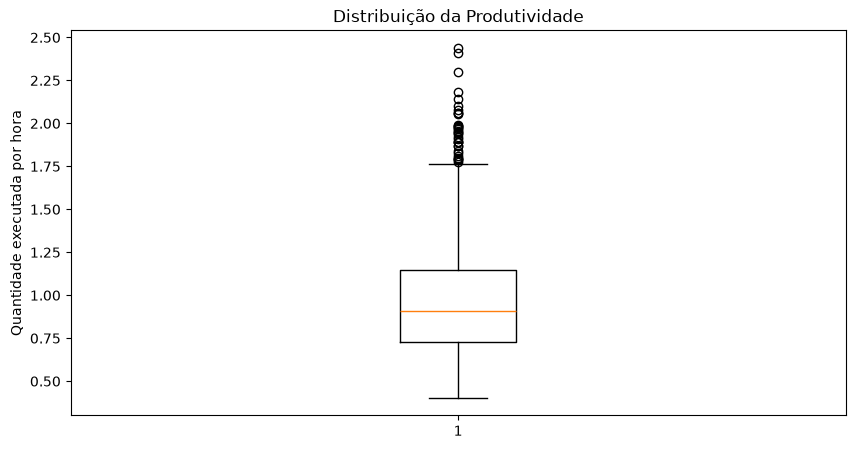

In [240]:
plt.figure(figsize=(10,5))

plt.boxplot(df_tratado["produtividade"])

plt.title("Distribuição da Produtividade")
plt.ylabel("Quantidade executada por hora")

plt.show()

In [2]:
from pathlib import Path

caminho_csv = Path("../data/processed/obras_produtividade_tratado.csv")

df_tratado.to_csv(
    caminho_csv,
    index=False,
    encoding="utf-8-sig"
)

NameError: name 'df_tratado' is not defined

In [242]:
df_tratado.head()

,id_registro,obra,cidade,data,equipe,trabalhadores,servico,condicao_climatica,horas_trabalhadas,quantidade_planejada,...,horas_retrabalho,indice_qualidade,ano,mes,mes_ano,produtividade,custo_por_unidade,desvio_quantidade_pct,status_atraso,faixa_qualidade
0,1,Condomínio Vila Verde,Vitória,2025-05-23,Equipe B,10,Instalações Hidráulicas,Chuva,83.5,50.7,...,0.7,100.0,2025,5,2025-05,0.644311,162.667100,6.114398,Com atraso,Alta
1,2,Residencial Vitória Park,Vitória,2025-01-31,Equipe D,8,Acabamento,Normal,69.4,34.8,...,2.3,88.8,2025,1,2025-01,0.727666,105.921980,45.114943,No prazo,Média
2,3,Residencial Parque Azul,Linhares,2026-03-06,Equipe A,8,Acabamento,Normal,51.9,34.2,...,0.3,100.0,2026,3,2026-03,0.599229,112.765273,-9.064327,No prazo,Alta
3,4,Edifício Atlântico,Serra,2025-12-15,Equipe B,11,Fundação,Normal,86.4,96.2,...,0.0,100.0,2025,12,2025-12,0.894676,306.063777,-19.646570,Com atraso,Alta
4,5,Residencial Parque Azul,Serra,2025-04-10,Equipe A,9,Estrutura,Normal,67.8,75.8,...,0.0,100.0,2025,4,2025-04,0.979351,470.754669,-12.401055,Com atraso,Alta


In [243]:
df_tratado.shape

(1200, 24)

In [244]:
print("Custo total:", df_tratado["custo_realizado"].sum())
print("Quantidade executada:", df_tratado["quantidade_executada"].sum())
print("Horas trabalhadas:", df_tratado["horas_trabalhadas"].sum())
print("Produtividade média:", df_tratado["produtividade"].mean())
print("Atraso médio:", df_tratado["dias_atraso"].mean())
print("Qualidade média:", df_tratado["indice_qualidade"].mean())

Custo total: 14814979.27
Quantidade executada: 72010.19999999998
Horas trabalhadas: 76780.2
Produtividade média: 0.9768461334391335
Atraso médio: 2.8525
Qualidade média: 95.02525


In [245]:
produtividade_servico = (
    df_tratado
    .groupby("servico")
    .agg(
        quantidade_executada=("quantidade_executada", "sum"),
        horas_trabalhadas=("horas_trabalhadas", "sum"),
        custo_total=("custo_realizado", "sum"),
        atraso_medio=("dias_atraso", "mean")
    )
)

In [246]:
produtividade_servico["produtividade"] = (
    produtividade_servico["quantidade_executada"] /
    produtividade_servico["horas_trabalhadas"]
)

In [247]:
produtividade_servico.sort_values(
    "produtividade",
    ascending=False
)

,quantidade_executada,horas_trabalhadas,custo_total,atraso_medio,produtividade
servico,,,,,
Fundação,10833.8,7483.3,3441667.78,3.333333,1.447730
Estrutura,9796.3,8518.0,3982732.79,3.015504,1.150070
Alvenaria,7735.2,6943.8,1397623.60,2.371681,1.113972
Pavimentação,9190.6,9165.0,1179089.93,2.873239,1.002793
Revestimento,5511.3,6655.4,667106.26,2.932692,0.828094
Cobertura,6961.4,8447.8,1463833.44,2.738806,0.824049
Pintura,6185.3,7780.3,528363.74,2.857143,0.794995
Instalações Elétricas,5079.9,6697.8,791723.45,2.737864,0.758443
Instalações Hidráulicas,5080.6,6759.7,746037.00,2.858491,0.751601


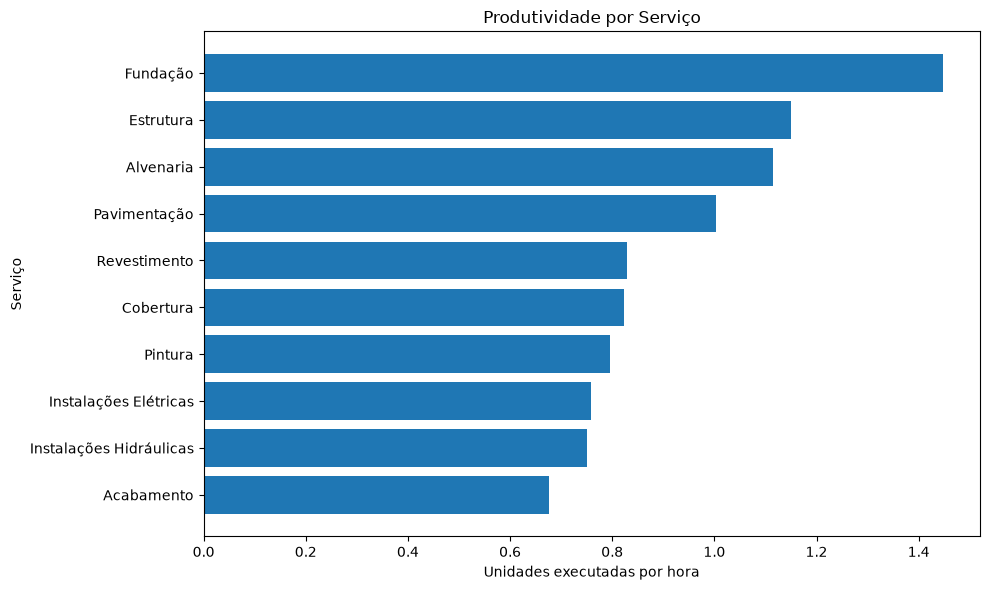

In [248]:
grafico = produtividade_servico.sort_values(
    "produtividade"
)

plt.figure(figsize=(10, 6))

plt.barh(
    grafico.index,
    grafico["produtividade"]
)

plt.title("Produtividade por Serviço")
plt.xlabel("Unidades executadas por hora")
plt.ylabel("Serviço")

plt.tight_layout()
plt.show()

In [249]:
df_tratado.groupby("servico")["quantidade_executada"].sum().sort_values(
    ascending=False
)

servico
Fundação                   10833.8
Estrutura                   9796.3
Pavimentação                9190.6
Alvenaria                   7735.2
Cobertura                   6961.4
Pintura                     6185.3
Acabamento                  5635.8
Revestimento                5511.3
Instalações Hidráulicas     5080.6
Instalações Elétricas       5079.9
Name: quantidade_executada, dtype: float64

In [250]:
produtividade_equipe = (
    df_tratado
    .groupby("equipe")
    .agg(
        quantidade_executada=("quantidade_executada", "sum"),
        horas_trabalhadas=("horas_trabalhadas", "sum"),
        custo_total=("custo_realizado", "sum"),
        atraso_medio=("dias_atraso", "mean")
    )
)

In [251]:
produtividade_equipe["produtividade"] = (
    produtividade_equipe["quantidade_executada"] /
    produtividade_equipe["horas_trabalhadas"]
)

In [252]:
produtividade_equipe.sort_values(
    "produtividade",
    ascending=False
)

,quantidade_executada,horas_trabalhadas,custo_total,atraso_medio,produtividade
equipe,,,,,
Equipe E,13853.7,11140.1,2764650.56,3.111111,1.243588
Equipe C,14236.6,13333.8,2863318.39,2.641667,1.067708
Equipe A,13166.9,13633.4,2820689.32,2.748837,0.965783
Equipe D,15518.4,18500.2,3069482.42,2.801556,0.838823
Equipe B,15234.6,20172.7,3296838.58,2.952756,0.755209


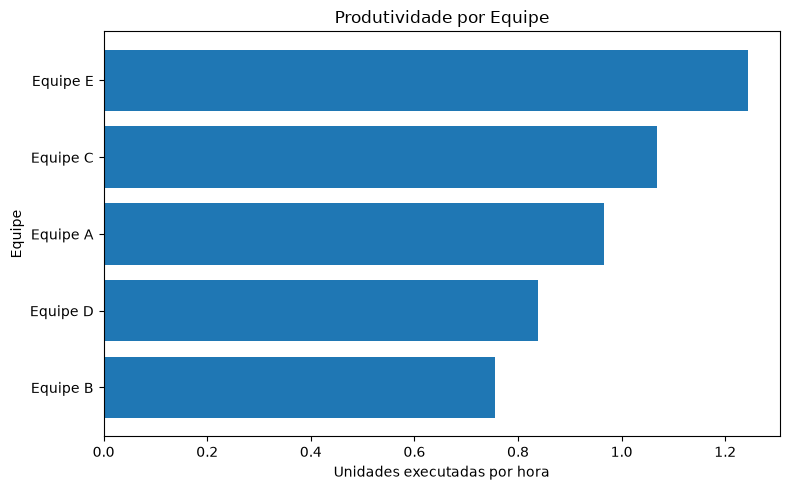

In [253]:
grafico = produtividade_equipe.sort_values(
    "produtividade"
)

plt.figure(figsize=(8, 5))

plt.barh(
    grafico.index,
    grafico["produtividade"]
)

plt.title("Produtividade por Equipe")
plt.xlabel("Unidades executadas por hora")
plt.ylabel("Equipe")

plt.tight_layout()
plt.show()

In [254]:
custo_obras = (
    df_tratado
    .groupby(["obra", "cidade"])
    .agg(
        custo_total=("custo_realizado", "sum"),
        quantidade_executada=("quantidade_executada", "sum"),
        atraso_medio=("dias_atraso", "mean"),
        qualidade_media=("indice_qualidade", "mean")
    )
    .sort_values("custo_total", ascending=False)
)

custo_obras

,,custo_total,quantidade_executada,atraso_medio,qualidade_media
obra,cidade,,,,
Residencial Monte Belo,Cariacica,462799.19,1802.5,2.413793,96.913793
Condomínio Alameda,Vitória,454709.22,1931.1,2.300000,95.743333
Residencial Monte Belo,Serra,396569.27,2097.9,2.314286,95.160000
Residencial Vitória Park,Cariacica,381191.25,1842.7,2.967742,95.625806
Edifício Atlântico,Linhares,368171.83,1630.1,3.037037,94.200000
Edifício Costa Norte,Colatina,358290.72,1477.6,3.608696,96.739130
Residencial Jardim das Acácias,Vila Velha,343701.89,1580.9,3.083333,96.304167
Edifício Horizonte,Linhares,329972.95,1541.5,2.782609,94.986957
Edifício Costa Norte,Cariacica,329448.64,1371.3,3.409091,94.190909


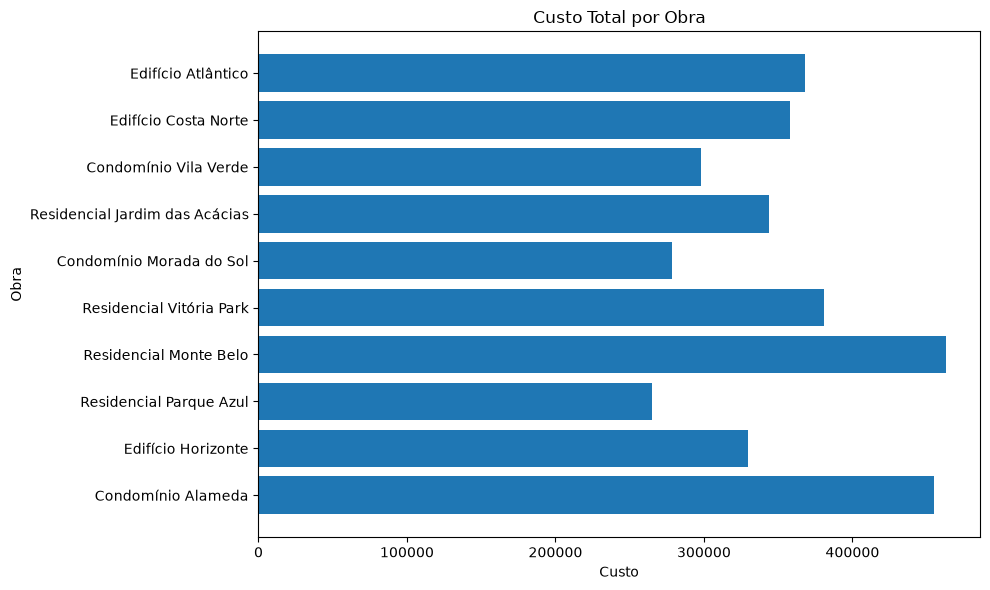

In [255]:
grafico = custo_obras.sort_values("custo_total")

plt.figure(figsize=(10, 6))

plt.barh(
    grafico.index.get_level_values("obra"),
    grafico["custo_total"]
)

plt.title("Custo Total por Obra")
plt.xlabel("Custo")
plt.ylabel("Obra")

plt.tight_layout()
plt.show()

In [256]:
custo_servico = (
    df_tratado
    .groupby("servico")
    .agg(
        custo_total=("custo_realizado", "sum"),
        quantidade=("quantidade_executada", "sum")
    )
)

custo_servico["custo_por_unidade"] = (
    custo_servico["custo_total"] /
    custo_servico["quantidade"]
)

custo_servico.sort_values(
    "custo_por_unidade",
    ascending=False
)

,custo_total,quantidade,custo_por_unidade
servico,,,
Estrutura,3982732.79,9796.3,406.554800
Fundação,3441667.78,10833.8,317.678726
Cobertura,1463833.44,6961.4,210.278599
Alvenaria,1397623.60,7735.2,180.683576
Instalações Elétricas,791723.45,5079.9,155.854141
Instalações Hidráulicas,746037.00,5080.6,146.840334
Pavimentação,1179089.93,9190.6,128.293031
Revestimento,667106.26,5511.3,121.043358
Acabamento,616801.28,5635.8,109.443430


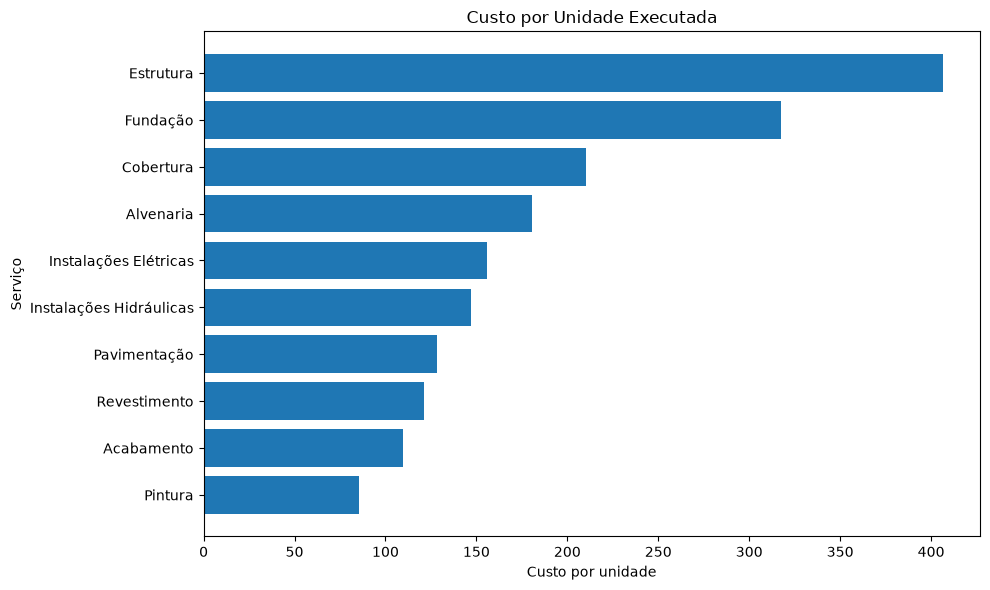

In [257]:
grafico = custo_servico.sort_values(
    "custo_por_unidade"
)

plt.figure(figsize=(10, 6))

plt.barh(
    grafico.index,
    grafico["custo_por_unidade"]
)

plt.title("Custo por Unidade Executada")
plt.xlabel("Custo por unidade")
plt.ylabel("Serviço")

plt.tight_layout()
plt.show()

In [258]:
df_tratado["status_atraso"].value_counts()

status_atraso
Com atraso    822
No prazo      378
Name: count, dtype: int64

In [259]:
percentual_atraso = (
    df_tratado["status_atraso"]
    .value_counts(normalize=True)
    * 100
)

percentual_atraso

status_atraso
Com atraso    68.5
No prazo      31.5
Name: proportion, dtype: float64

In [260]:
atraso_clima = (
    df_tratado
    .groupby("condicao_climatica")
    .agg(
        atraso_medio=("dias_atraso", "mean"),
        produtividade=("produtividade", "mean"),
        registros=("id_registro", "count")
    )
    .sort_values("atraso_medio", ascending=False)
)

atraso_clima

,atraso_medio,produtividade,registros
condicao_climatica,,,
Chuva intensa,7.594203,0.988676,69
Chuva,4.475836,0.976802,269
Normal,1.966357,0.975913,862


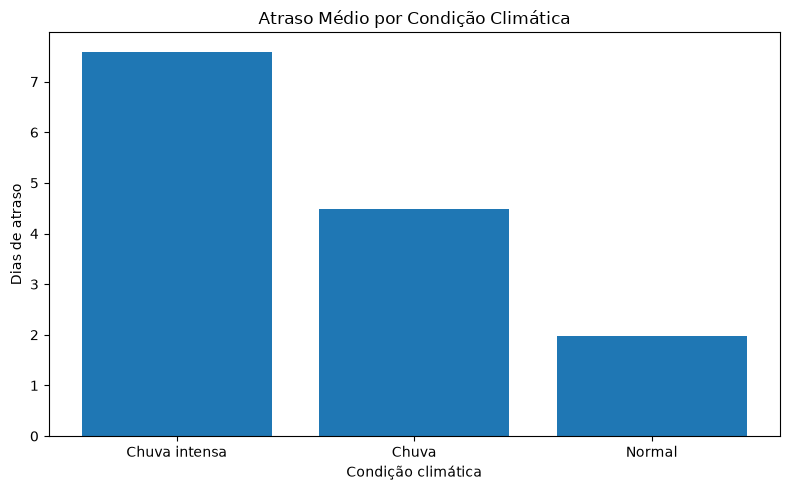

In [261]:
plt.figure(figsize=(8, 5))

plt.bar(
    atraso_clima.index,
    atraso_clima["atraso_medio"]
)

plt.title("Atraso Médio por Condição Climática")
plt.xlabel("Condição climática")
plt.ylabel("Dias de atraso")

plt.tight_layout()
plt.show()

In [262]:
retrabalho = (
    df_tratado
    .groupby("servico")
    .agg(
        retrabalho=("horas_retrabalho", "mean"),
        qualidade=("indice_qualidade", "mean")
    )
)

retrabalho.sort_values(
    "retrabalho",
    ascending=False
)

,retrabalho,qualidade
servico,,
Revestimento,2.217308,92.780769
Acabamento,2.151163,92.828682
Pintura,2.110317,92.977778
Estrutura,1.208527,95.900775
Pavimentação,1.204225,95.911268
Alvenaria,1.173451,95.927434
Cobertura,1.164179,96.004478
Instalações Hidráulicas,1.124528,95.730189
Instalações Elétricas,1.114563,96.010680


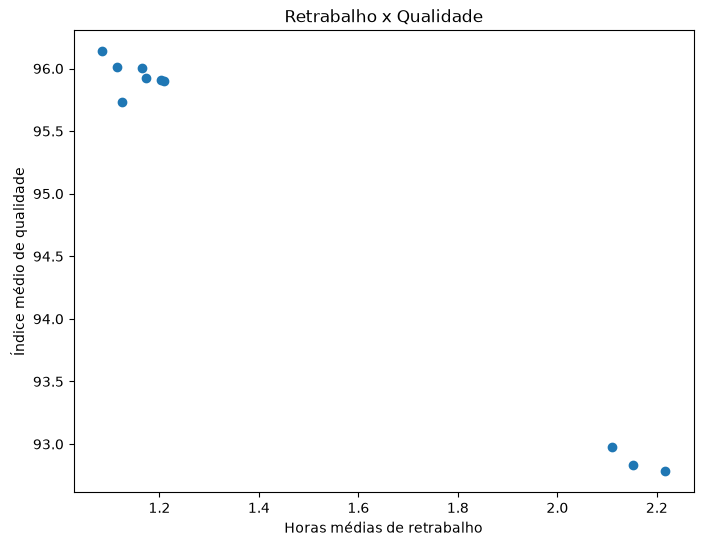

In [263]:
plt.figure(figsize=(8, 6))

plt.scatter(
    retrabalho["retrabalho"],
    retrabalho["qualidade"]
)

plt.xlabel("Horas médias de retrabalho")
plt.ylabel("Índice médio de qualidade")
plt.title("Retrabalho x Qualidade")

plt.show()

In [264]:
correlacao = df_tratado[
    ["horas_retrabalho", "indice_qualidade"]
].corr()

correlacao

,horas_retrabalho,indice_qualidade
horas_retrabalho,1.000000,-0.879873
indice_qualidade,-0.879873,1.000000


In [265]:
evolucao = (
    df_tratado
    .groupby("mes_ano")
    .agg(
        custo=("custo_realizado", "sum"),
        quantidade=("quantidade_executada", "sum"),
        horas=("horas_trabalhadas", "sum"),
        atraso=("dias_atraso", "mean")
    )
)

In [266]:
evolucao["produtividade"] = (
    evolucao["quantidade"] /
    evolucao["horas"]
)

In [267]:
evolucao.head()

,custo,quantidade,horas,atraso,produtividade
mes_ano,,,,,
2025-01,723456.82,3658.9,4016.3,3.067797,0.911013
2025-02,692072.33,3265.4,3351.0,2.773585,0.974455
2025-03,692979.07,4035.4,4279.1,2.414286,0.943049
2025-04,1006483.92,4681.3,4972.4,3.076923,0.941457
2025-05,839474.75,3896.9,4064.9,3.125000,0.958671


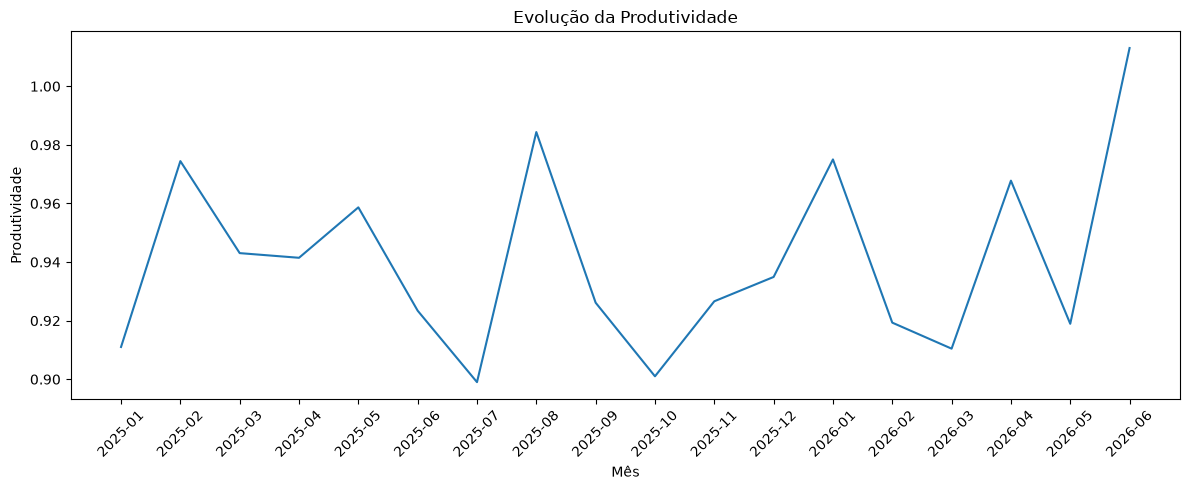

In [268]:
plt.figure(figsize=(12, 5))

plt.plot(
    evolucao.index,
    evolucao["produtividade"]
)

plt.title("Evolução da Produtividade")
plt.xlabel("Mês")
plt.ylabel("Produtividade")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [269]:
planejado_realizado = (
    df_tratado
    .groupby("servico")
    .agg(
        planejado=("quantidade_planejada", "sum"),
        realizado=("quantidade_executada", "sum")
    )
)

planejado_realizado

,planejado,realizado
servico,,
Acabamento,4922.1,5635.8
Alvenaria,7321.0,7735.2
Cobertura,7646.4,6961.4
Estrutura,10212.7,9796.3
Fundação,10852.6,10833.8
Instalações Elétricas,5686.4,5079.9
Instalações Hidráulicas,5406.1,5080.6
Pavimentação,8510.3,9190.6
Pintura,5208.4,6185.3


In [270]:
planejado_realizado["desvio_pct"] = (
    (
        planejado_realizado["realizado"] -
        planejado_realizado["planejado"]
    )
    / planejado_realizado["planejado"]
) * 100

In [271]:
planejado_realizado.sort_values(
    "desvio_pct"
)

,planejado,realizado,desvio_pct
servico,,,
Instalações Elétricas,5686.4,5079.9,-10.665799
Cobertura,7646.4,6961.4,-8.958464
Instalações Hidráulicas,5406.1,5080.6,-6.020976
Estrutura,10212.7,9796.3,-4.077276
Fundação,10852.6,10833.8,-0.173230
Alvenaria,7321.0,7735.2,5.657697
Pavimentação,8510.3,9190.6,7.993843
Revestimento,4974.5,5511.3,10.791034
Acabamento,4922.1,5635.8,14.499909


In [272]:
resumo_servicos = (
    df_tratado
    .groupby("servico")
    .agg(
        quantidade_executada=("quantidade_executada", "sum"),
        horas_trabalhadas=("horas_trabalhadas", "sum"),
        custo_total=("custo_realizado", "sum"),
        atraso_medio=("dias_atraso", "mean"),
        retrabalho_medio=("horas_retrabalho", "mean"),
        qualidade_media=("indice_qualidade", "mean")
    )
)

resumo_servicos["produtividade"] = (
    resumo_servicos["quantidade_executada"] /
    resumo_servicos["horas_trabalhadas"]
)

resumo_servicos["custo_por_unidade"] = (
    resumo_servicos["custo_total"] /
    resumo_servicos["quantidade_executada"]
)

resumo_servicos = resumo_servicos.sort_values(
    "produtividade",
    ascending=False
)

resumo_servicos

,quantidade_executada,horas_trabalhadas,custo_total,atraso_medio,retrabalho_medio,qualidade_media,produtividade,custo_por_unidade
servico,,,,,,,,
Fundação,10833.8,7483.3,3441667.78,3.333333,1.084211,96.135965,1.447730,317.678726
Estrutura,9796.3,8518.0,3982732.79,3.015504,1.208527,95.900775,1.150070,406.554800
Alvenaria,7735.2,6943.8,1397623.60,2.371681,1.173451,95.927434,1.113972,180.683576
Pavimentação,9190.6,9165.0,1179089.93,2.873239,1.204225,95.911268,1.002793,128.293031
Revestimento,5511.3,6655.4,667106.26,2.932692,2.217308,92.780769,0.828094,121.043358
Cobertura,6961.4,8447.8,1463833.44,2.738806,1.164179,96.004478,0.824049,210.278599
Pintura,6185.3,7780.3,528363.74,2.857143,2.110317,92.977778,0.794995,85.422492
Instalações Elétricas,5079.9,6697.8,791723.45,2.737864,1.114563,96.010680,0.758443,155.854141
Instalações Hidráulicas,5080.6,6759.7,746037.00,2.858491,1.124528,95.730189,0.751601,146.840334


In [273]:
resumo_equipes = (
    df_tratado
    .groupby("equipe")
    .agg(
        quantidade_executada=("quantidade_executada", "sum"),
        horas_trabalhadas=("horas_trabalhadas", "sum"),
        custo_total=("custo_realizado", "sum"),
        atraso_medio=("dias_atraso", "mean"),
        qualidade_media=("indice_qualidade", "mean")
    )
)

resumo_equipes["produtividade"] = (
    resumo_equipes["quantidade_executada"] /
    resumo_equipes["horas_trabalhadas"]
)

resumo_equipes["custo_por_unidade"] = (
    resumo_equipes["custo_total"] /
    resumo_equipes["quantidade_executada"]
)

resumo_equipes.sort_values(
    "produtividade",
    ascending=False
)

,quantidade_executada,horas_trabalhadas,custo_total,atraso_medio,qualidade_media,produtividade,custo_por_unidade
equipe,,,,,,,
Equipe E,13853.7,11140.1,2764650.56,3.111111,95.222222,1.243588,199.560447
Equipe C,14236.6,13333.8,2863318.39,2.641667,94.780000,1.067708,201.123751
Equipe A,13166.9,13633.4,2820689.32,2.748837,95.061860,0.965783,214.225772
Equipe D,15518.4,18500.2,3069482.42,2.801556,95.147471,0.838823,197.796320
Equipe B,15234.6,20172.7,3296838.58,2.952756,94.920866,0.755209,216.404670


In [274]:
import os

os.makedirs("resultados_eda", exist_ok=True)

In [275]:
resumo_servicos.to_csv(
    "resultados_eda/resumo_servicos.csv",
    encoding="utf-8-sig"
)

resumo_equipes.to_csv(
    "resultados_eda/resumo_equipes.csv",
    encoding="utf-8-sig"
)

In [276]:
pd.crosstab(
    df_tratado["equipe"],
    df_tratado["servico"]
)

servico,Acabamento,Alvenaria,Cobertura,Estrutura,Fundação,Instalações Elétricas,Instalações Hidráulicas,Pavimentação,Pintura,Revestimento
equipe,,,,,,,,,,
Equipe A,16,30,28,28,18,18,17,24,16,20
Equipe B,31,13,23,35,28,25,30,31,20,18
Equipe C,19,23,31,21,24,23,15,26,37,21
Equipe D,34,23,26,23,23,21,18,33,27,29
Equipe E,29,24,26,22,21,16,26,28,26,16


In [277]:
pd.crosstab(
    df_tratado["equipe"],
    df_tratado["servico"],
    normalize="index"
) * 100

servico,Acabamento,Alvenaria,Cobertura,Estrutura,Fundação,Instalações Elétricas,Instalações Hidráulicas,Pavimentação,Pintura,Revestimento
equipe,,,,,,,,,,
Equipe A,7.441860,13.953488,13.023256,13.023256,8.372093,8.372093,7.906977,11.162791,7.441860,9.302326
Equipe B,12.204724,5.118110,9.055118,13.779528,11.023622,9.842520,11.811024,12.204724,7.874016,7.086614
Equipe C,7.916667,9.583333,12.916667,8.750000,10.000000,9.583333,6.250000,10.833333,15.416667,8.750000
Equipe D,13.229572,8.949416,10.116732,8.949416,8.949416,8.171206,7.003891,12.840467,10.505837,11.284047
Equipe E,12.393162,10.256410,11.111111,9.401709,8.974359,6.837607,11.111111,11.965812,11.111111,6.837607


In [278]:
import sqlite3

In [1]:
from pathlib import Path
import sqlite3

caminho_banco = Path("../data/processed/obras.db")
conexao = sqlite3.connect(caminho_banco)

In [280]:
df_tratado.to_sql(
    "obras_produtividade",
    conexao,
    if_exists="replace",
    index=False
)

1200

In [281]:
consulta = """
SELECT *
FROM obras_produtividade
LIMIT 10;
"""

resultado = pd.read_sql_query(
    consulta,
    conexao
)

resultado

,id_registro,obra,cidade,data,equipe,trabalhadores,servico,condicao_climatica,horas_trabalhadas,quantidade_planejada,...,horas_retrabalho,indice_qualidade,ano,mes,mes_ano,produtividade,custo_por_unidade,desvio_quantidade_pct,status_atraso,faixa_qualidade
0,1,Condomínio Vila Verde,Vitória,2025-05-23 00:00:00,Equipe B,10,Instalações Hidráulicas,Chuva,83.5,50.7,...,0.7,100.0,2025,5,2025-05,0.644311,162.667100,6.114398,Com atraso,Alta
1,2,Residencial Vitória Park,Vitória,2025-01-31 00:00:00,Equipe D,8,Acabamento,Normal,69.4,34.8,...,2.3,88.8,2025,1,2025-01,0.727666,105.921980,45.114943,No prazo,Média
2,3,Residencial Parque Azul,Linhares,2026-03-06 00:00:00,Equipe A,8,Acabamento,Normal,51.9,34.2,...,0.3,100.0,2026,3,2026-03,0.599229,112.765273,-9.064327,No prazo,Alta
3,4,Edifício Atlântico,Serra,2025-12-15 00:00:00,Equipe B,11,Fundação,Normal,86.4,96.2,...,0.0,100.0,2025,12,2025-12,0.894676,306.063777,-19.646570,Com atraso,Alta
4,5,Residencial Parque Azul,Serra,2025-04-10 00:00:00,Equipe A,9,Estrutura,Normal,67.8,75.8,...,0.0,100.0,2025,4,2025-04,0.979351,470.754669,-12.401055,Com atraso,Alta
5,6,Edifício Horizonte,Linhares,2025-05-08 00:00:00,Equipe A,9,Instalações Hidráulicas,Chuva intensa,63.5,54.0,...,1.9,91.3,2025,5,2025-05,0.508661,129.593189,-40.185185,Com atraso,Alta
6,7,Residencial Monte Belo,Vitória,2025-07-16 00:00:00,Equipe C,7,Cobertura,Normal,55.2,54.9,...,2.3,93.3,2025,7,2025-07,0.750000,197.906522,-24.590164,No prazo,Alta
7,8,Residencial Jardim das Acácias,Colatina,2025-08-27 00:00:00,Equipe C,6,Instalações Elétricas,Chuva,35.7,58.2,...,2.2,94.8,2025,8,2025-08,0.983193,146.606268,-39.690722,Com atraso,Alta
8,9,Residencial Monte Belo,Serra,2026-01-15 00:00:00,Equipe C,7,Pavimentação,Normal,50.1,56.7,...,0.8,95.2,2026,1,2026-01,1.203593,140.145605,6.349206,No prazo,Alta
9,10,Condomínio Morada do Sol,Colatina,2025-09-08 00:00:00,Equipe E,6,Estrutura,Normal,39.6,91.7,...,1.4,94.2,2025,9,2025-09,1.840909,407.638134,-20.501636,Com atraso,Alta


In [282]:
consulta = """
SELECT
    obra,
    cidade,
    equipe,
    servico,
    custo_realizado
FROM obras_produtividade
LIMIT 10;
"""

pd.read_sql_query(consulta, conexao)

,obra,cidade,equipe,servico,custo_realizado
0,Condomínio Vila Verde,Vitória,Equipe B,Instalações Hidráulicas,8751.49
1,Residencial Vitória Park,Vitória,Equipe D,Acabamento,5349.06
2,Residencial Parque Azul,Linhares,Equipe A,Acabamento,3507.00
3,Edifício Atlântico,Serra,Equipe B,Fundação,23658.73
4,Residencial Parque Azul,Serra,Equipe A,Estrutura,31258.11
5,Edifício Horizonte,Linhares,Equipe A,Instalações Hidráulicas,4185.86
6,Residencial Monte Belo,Vitória,Equipe C,Cobertura,8193.33
7,Residencial Jardim das Acácias,Colatina,Equipe C,Instalações Elétricas,5145.88
8,Residencial Monte Belo,Serra,Equipe C,Pavimentação,8450.78
9,Condomínio Morada do Sol,Colatina,Equipe E,Estrutura,29716.82


In [283]:
consulta = """
SELECT
    obra,
    cidade,
    servico,
    custo_realizado
FROM obras_produtividade
WHERE cidade = 'Vitória';
"""

pd.read_sql_query(consulta, conexao)

,obra,cidade,servico,custo_realizado
0,Condomínio Vila Verde,Vitória,Instalações Hidráulicas,8751.49
1,Residencial Vitória Park,Vitória,Acabamento,5349.06
2,Residencial Monte Belo,Vitória,Cobertura,8193.33
3,Condomínio Vila Verde,Vitória,Estrutura,33601.35
4,Condomínio Alameda,Vitória,Cobertura,13971.26
...,...,...,...,...
188,Residencial Monte Belo,Vitória,Estrutura,28634.64
189,Condomínio Alameda,Vitória,Revestimento,4792.96
190,Residencial Monte Belo,Vitória,Estrutura,36126.05
191,Residencial Jardim das Acácias,Vitória,Cobertura,15894.03


In [284]:
consulta = """
SELECT
    obra,
    equipe,
    servico,
    dias_atraso
FROM obras_produtividade
WHERE dias_atraso > 0;
"""

pd.read_sql_query(consulta, conexao)

,obra,equipe,servico,dias_atraso
0,Condomínio Vila Verde,Equipe B,Instalações Hidráulicas,4
1,Edifício Atlântico,Equipe B,Fundação,2
2,Residencial Parque Azul,Equipe A,Estrutura,1
3,Edifício Horizonte,Equipe A,Instalações Hidráulicas,9
4,Residencial Jardim das Acácias,Equipe C,Instalações Elétricas,6
...,...,...,...,...
817,Condomínio Morada do Sol,Equipe C,Pintura,4
818,Condomínio Vila Verde,Equipe C,Cobertura,2
819,Edifício Horizonte,Equipe D,Instalações Elétricas,8
820,Edifício Costa Norte,Equipe E,Fundação,6


In [285]:
consulta = """
SELECT
    obra,
    equipe,
    servico,
    dias_atraso
FROM obras_produtividade
ORDER BY dias_atraso DESC
LIMIT 10;
"""

pd.read_sql_query(consulta, conexao)

,obra,equipe,servico,dias_atraso
0,Residencial Monte Belo,Equipe B,Instalações Hidráulicas,13
1,Condomínio Alameda,Equipe B,Acabamento,13
2,Edifício Horizonte,Equipe C,Acabamento,13
3,Edifício Costa Norte,Equipe D,Pavimentação,12
4,Edifício Costa Norte,Equipe D,Revestimento,12
5,Edifício Atlântico,Equipe E,Revestimento,12
6,Edifício Atlântico,Equipe D,Revestimento,12
7,Residencial Vitória Park,Equipe E,Cobertura,12
8,Edifício Atlântico,Equipe E,Fundação,12
9,Condomínio Vila Verde,Equipe E,Pintura,11


In [286]:
consulta = """
SELECT
    obra,
    cidade,
    SUM(custo_realizado) AS custo_total
FROM obras_produtividade
GROUP BY
    obra,
    cidade
ORDER BY
    custo_total DESC;
"""

pd.read_sql_query(consulta, conexao)

,obra,cidade,custo_total
0,Residencial Monte Belo,Cariacica,462799.19
1,Condomínio Alameda,Vitória,454709.22
2,Residencial Monte Belo,Serra,396569.27
3,Residencial Vitória Park,Cariacica,381191.25
4,Edifício Atlântico,Linhares,368171.83
5,Edifício Costa Norte,Colatina,358290.72
6,Residencial Jardim das Acácias,Vila Velha,343701.89
7,Edifício Horizonte,Linhares,329972.95
8,Edifício Costa Norte,Cariacica,329448.64
9,Residencial Vitória Park,Vitória,316540.41


In [287]:
consulta = """
SELECT
    equipe,
    SUM(quantidade_executada) AS quantidade_total,
    SUM(horas_trabalhadas) AS horas_total,

    SUM(quantidade_executada)
        / SUM(horas_trabalhadas) AS produtividade

FROM obras_produtividade

GROUP BY equipe

ORDER BY produtividade DESC;
"""

pd.read_sql_query(consulta, conexao)

,equipe,quantidade_total,horas_total,produtividade
0,Equipe E,13853.7,11140.1,1.243588
1,Equipe C,14236.6,13333.8,1.067708
2,Equipe A,13166.9,13633.4,0.965783
3,Equipe D,15518.4,18500.2,0.838823
4,Equipe B,15234.6,20172.7,0.755209


In [288]:
consulta = """
SELECT
    equipe,

    ROUND(
        SUM(quantidade_executada)
        / SUM(horas_trabalhadas),
        2
    ) AS produtividade

FROM obras_produtividade

GROUP BY equipe

ORDER BY produtividade DESC;
"""

pd.read_sql_query(consulta, conexao)

,equipe,produtividade
0,Equipe E,1.24
1,Equipe C,1.07
2,Equipe A,0.97
3,Equipe D,0.84
4,Equipe B,0.76


In [289]:
consulta = """
SELECT
    servico,

    ROUND(SUM(custo_realizado), 2)
        AS custo_total,

    ROUND(SUM(quantidade_executada), 2)
        AS quantidade_total,

    ROUND(
        SUM(custo_realizado)
        / SUM(quantidade_executada),
        2
    ) AS custo_por_unidade

FROM obras_produtividade

GROUP BY servico

ORDER BY custo_por_unidade DESC;
"""

pd.read_sql_query(consulta, conexao)

,servico,custo_total,quantidade_total,custo_por_unidade
0,Estrutura,3982732.79,9796.3,406.55
1,Fundação,3441667.78,10833.8,317.68
2,Cobertura,1463833.44,6961.4,210.28
3,Alvenaria,1397623.60,7735.2,180.68
4,Instalações Elétricas,791723.45,5079.9,155.85
5,Instalações Hidráulicas,746037.00,5080.6,146.84
6,Pavimentação,1179089.93,9190.6,128.29
7,Revestimento,667106.26,5511.3,121.04
8,Acabamento,616801.28,5635.8,109.44
9,Pintura,528363.74,6185.3,85.42


In [290]:
consulta = """
SELECT
    id_registro,
    obra,
    equipe,
    dias_atraso,

    CASE
        WHEN dias_atraso > 0 THEN 'Com atraso'
        ELSE 'No prazo'
    END AS status_atraso

FROM obras_produtividade
LIMIT 20;
"""

pd.read_sql_query(consulta, conexao)

,id_registro,obra,equipe,dias_atraso,status_atraso
0,1,Condomínio Vila Verde,Equipe B,4,Com atraso
1,2,Residencial Vitória Park,Equipe D,0,No prazo
2,3,Residencial Parque Azul,Equipe A,0,No prazo
3,4,Edifício Atlântico,Equipe B,2,Com atraso
4,5,Residencial Parque Azul,Equipe A,1,Com atraso
5,6,Edifício Horizonte,Equipe A,9,Com atraso
6,7,Residencial Monte Belo,Equipe C,0,No prazo
7,8,Residencial Jardim das Acácias,Equipe C,6,Com atraso
8,9,Residencial Monte Belo,Equipe C,0,No prazo
9,10,Condomínio Morada do Sol,Equipe E,5,Com atraso


In [291]:
consulta = """
SELECT
    condicao_climatica,

    COUNT(*) AS registros,

    ROUND(
        AVG(dias_atraso),
        2
    ) AS atraso_medio,

    ROUND(
        SUM(quantidade_executada)
        / SUM(horas_trabalhadas),
        2
    ) AS produtividade

FROM obras_produtividade

GROUP BY condicao_climatica

ORDER BY atraso_medio DESC;
"""

pd.read_sql_query(consulta, conexao)

,condicao_climatica,registros,atraso_medio,produtividade
0,Chuva intensa,69,7.59,0.95
1,Chuva,269,4.48,0.94
2,Normal,862,1.97,0.94


In [292]:
consulta = """
WITH produtividade_equipes AS (

    SELECT
        equipe,

        SUM(quantidade_executada)
        / SUM(horas_trabalhadas)
        AS produtividade

    FROM obras_produtividade

    GROUP BY equipe
)

SELECT
    equipe,
    ROUND(produtividade, 2) AS produtividade
FROM produtividade_equipes
ORDER BY produtividade DESC;
"""

pd.read_sql_query(consulta, conexao)

,equipe,produtividade
0,Equipe E,1.24
1,Equipe C,1.07
2,Equipe A,0.97
3,Equipe D,0.84
4,Equipe B,0.76


In [293]:
consulta = """
WITH produtividade_equipes AS (

    SELECT
        equipe,

        SUM(quantidade_executada)
        / SUM(horas_trabalhadas)
        AS produtividade

    FROM obras_produtividade

    GROUP BY equipe
)

SELECT
    equipe,

    ROUND(produtividade, 2)
        AS produtividade,

    RANK() OVER (
        ORDER BY produtividade DESC
    ) AS ranking

FROM produtividade_equipes

ORDER BY ranking;
"""

pd.read_sql_query(consulta, conexao)

,equipe,produtividade,ranking
0,Equipe E,1.24,1
1,Equipe C,1.07,2
2,Equipe A,0.97,3
3,Equipe D,0.84,4
4,Equipe B,0.76,5


In [294]:
consulta = """
SELECT

    strftime('%Y-%m', data) AS mes,

    ROUND(
        SUM(quantidade_executada)
        / SUM(horas_trabalhadas),
        2
    ) AS produtividade,

    ROUND(
        SUM(custo_realizado),
        2
    ) AS custo_total,

    ROUND(
        AVG(dias_atraso),
        2
    ) AS atraso_medio

FROM obras_produtividade

GROUP BY mes

ORDER BY mes;
"""

evolucao_sql = pd.read_sql_query(
    consulta,
    conexao
)

evolucao_sql

,mes,produtividade,custo_total,atraso_medio
0,2025-01,0.94,1691062.58,2.92
1,2025-02,0.95,1275896.63,2.51
2,2025-04,0.95,1898353.30,3.23
3,2025-05,0.94,1650163.69,3.34
4,2025-07,0.90,770430.42,2.47
5,2025-08,0.98,850492.82,3.62
6,2025-09,0.93,786761.02,2.89
7,2025-10,0.90,778779.36,2.53
8,2025-11,0.93,866157.42,2.51
9,2025-12,0.93,1057153.51,3.52


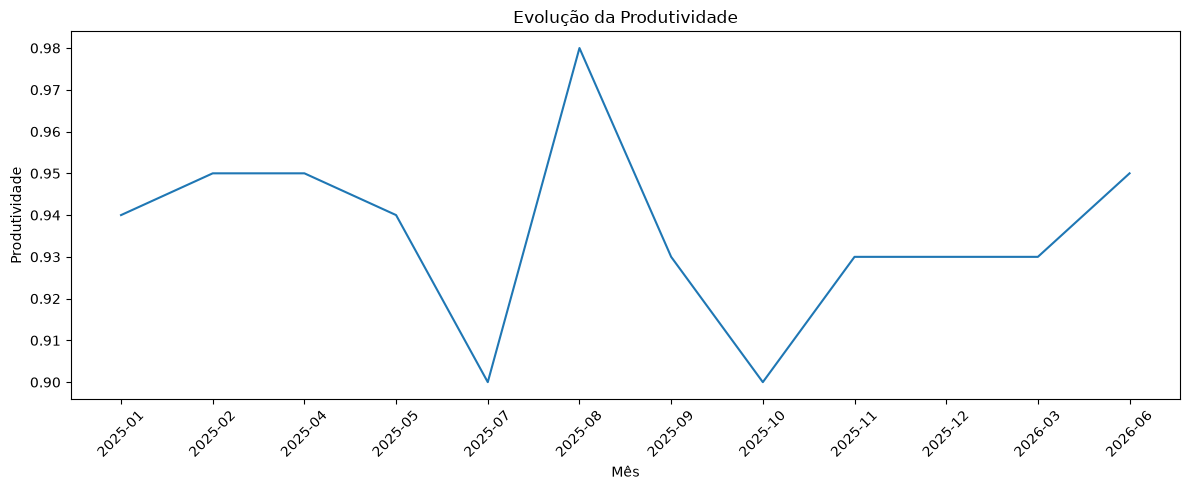

In [295]:
plt.figure(figsize=(12, 5))

plt.plot(
    evolucao_sql["mes"],
    evolucao_sql["produtividade"]
)

plt.title("Evolução da Produtividade")
plt.xlabel("Mês")
plt.ylabel("Produtividade")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [297]:
import sqlite3
from pathlib import Path

caminho_banco = Path("../data/processed/obras.db")

conexao = sqlite3.connect(caminho_banco)

print(pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conexao
))

conexao.close()

                  name
0  obras_produtividade


In [298]:
conexao = sqlite3.connect(caminho_banco)

consulta = """
SELECT
    COUNT(*) AS quantidade_registros,
    ROUND(SUM(custo_realizado), 2) AS custo_total,
    ROUND(SUM(quantidade_planejada), 2) AS quantidade_planejada,
    ROUND(SUM(quantidade_executada), 2) AS quantidade_executada,
    ROUND(AVG(dias_atraso), 2) AS atraso_medio
FROM obras_produtividade;
"""

resultado = pd.read_sql_query(consulta, conexao)
display(resultado)

conexao.close()

,quantidade_registros,custo_total,quantidade_planejada,quantidade_executada,atraso_medio
0,1200,14814979.27,70740.5,72010.2,2.85
